# Week 08 - CNN Classification II | YCB-V BOP'19
**Intern: Mehrana Rezaei | Group 1 | Main Quest: Convolutional Neural Networks**

This notebook is a continuation of the **executed Week 07** work, not a new dataset/task.
Week 07 verified: 877/375/450 samples; five object IDs [4,3,1,6,12];
64x64 8%-padded letterbox; held-out accuracy 0.7267 and macro-F1 0.7132.

Week 08 compares (i) a **retrained**, protocol-matched Week 07 CompactCNN
with (ii) an ImageNet-pretrained ResNet18 fine-tuned on the *same object crops*.
Both are evaluated under controlled synthetic perturbations and using real BOP
geometry, visibility and scene clutter annotations.

Important research limitations:
- No original Week 07 .pt checkpoint was included in its ZIP. The old score is
  historical evidence, **not** the result of an identical saved model evaluated here.
- The `ycbv/test` folder belongs to the public BOP'19 *source archive*; the
  internal held-out scenes are NOT an official BOP challenge evaluation.
- Scenes 51/59 were already inspected in Week 07: they are an unchanged
  historical holdout, but no longer an **unseen-to-the-project** external test.
- Image rotations simulate in-plane orientation, NOT true novel 3D viewpoints.
- Synthetic occlusion and pasted clutter are controlled stress tests, not
  naturally collected occluded/cluttered ground-truth images.

## 1. Environment and reproducible settings
Run this notebook top-to-bottom in Google Colab with **GPU** enabled.
If a dataset already exists under `datasets/ycbv/test`, no download is needed.

In [1]:
import sys, subprocess, importlib.util
for module, package in [('huggingface_hub','huggingface_hub'),('reportlab','reportlab'),
                         ('sklearn','scikit-learn'),('docx','python-docx')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

In [2]:
import copy, hashlib, json, math, os, random, time, zipfile, shutil
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             precision_recall_fscore_support, classification_report)
from IPython.display import display

SEED = 42
CLASSES = ['tomato_soup_can','sugar_box','master_chef_can','tuna_fish_can','bleach_cleanser']
CLASS_IDS = [4,3,1,6,12]
CLASS_TO_INDEX = dict(zip(CLASS_IDS,range(5)))
YCBV_OBJECTS = {1:'master_chef_can',2:'cracker_box',3:'sugar_box',4:'tomato_soup_can',
                5:'mustard_bottle',6:'tuna_fish_can',7:'pudding_box',8:'gelatin_box',
                9:'potted_meat_can',10:'banana',11:'pitcher_base',12:'bleach_cleanser',
                13:'bowl',14:'mug',15:'power_drill',16:'wood_block',17:'scissors',
                18:'large_marker',19:'large_clamp',20:'extra_large_clamp',21:'foam_brick'}
FIXED_SCENES = {'train':[48,49,50,53,54,56,57,58], 'validation':[52,55], 'test':[51,59]}
EXPECTED_COUNTS = {'train':877,'validation':375,'test':450}
MAX_PER_CLASS = {'train':600,'validation':150,'test':150}
DATASET_ROOT = Path('datasets/ycbv')
OUT = Path('outputs/week08')
CKPT = OUT/'checkpoints'
for d in [OUT,CKPT]: d.mkdir(parents=True,exist_ok=True)
IMAGE_SIZE=64
BATCH_SIZE=64
NUM_WORKERS=0
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_FINAL_TEST = True  # Set False to produce a validation-only report.

def seed_everything(seed=SEED):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
seed_everything()
print('Device:',DEVICE, '| PyTorch:',torch.__version__,'| torchvision:',torchvision.__version__)
print('Classes:',dict(enumerate(CLASSES)))

Device: cpu | PyTorch: 2.11.0+cpu | torchvision: 0.26.0+cpu
Classes: {0: 'tomato_soup_can', 1: 'sugar_box', 2: 'master_chef_can', 3: 'tuna_fish_can', 4: 'bleach_cleanser'}


## 2. Load the exact Week 07 BOP19 source and freeze the original scene split
The split is *explicitly fixed* by scene IDs (not resampled after seeing test).
Dataset records retain pose, visibility, object-box scale and neighborhood counts.

In [3]:
from huggingface_hub import hf_hub_download

def dataset_ready(root):
    t=root/'test'
    return t.is_dir() and all((t/f'{s:06d}'/'scene_gt.json').exists()
                              for ids in FIXED_SCENES.values() for s in ids)
if not dataset_ready(DATASET_ROOT):
    print('Downloading original Week 07 BOP19 source archives (about 660 MB).')
    for filename in ['ycbv_base.zip','ycbv_test_bop19.zip']:
        try:
            src=hf_hub_download(repo_id='bop-benchmark/ycbv',filename=filename,repo_type='dataset')
        except Exception:
            src=hf_hub_download(repo_id='bop-benchmark/ycbv',filename=filename)
        with zipfile.ZipFile(src) as archive:
            archive.extractall(DATASET_ROOT)
assert dataset_ready(DATASET_ROOT), 'Missing one of the exact Week 07 scene directories.'
print('Dataset ready:',DATASET_ROOT.resolve())

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Dataset ready: /content/datasets/ycbv


In [4]:
def read_json(path):
    with open(path,encoding='utf8') as f: return json.load(f)

def bbox_intersects(a,b):
    ax,ay,aw,ah=a;bx,by,bw,bh=b
    return max(ax,bx)<min(ax+aw,bx+bw) and max(ay,by)<min(ay+ah,by+bh)

def table_for_scenes(root):
    rows=[]
    for sid in sorted(set(sum(FIXED_SCENES.values(),[]))):
        d=root/'test'/f'{sid:06d}'
        gt=read_json(d/'scene_gt.json')
        info=read_json(d/'scene_gt_info.json')
        for key,objects in gt.items():
            im_id=int(key);infos=info[key]
            rgb=d/'rgb'/f'{im_id:06d}.png'
            if not rgb.exists(): rgb=d/'rgb'/f'{im_id:06d}.jpg'
            if not rgb.exists(): continue
            all_bboxes=[v.get('bbox_obj') or v.get('bbox_visib') for v in infos]
            for instance_idx,(obj,meta) in enumerate(zip(objects,infos)):
                oid=int(obj['obj_id'])
                if oid not in CLASS_IDS: continue
                bbox=all_bboxes[instance_idx]
                if bbox is None: continue
                x,y,w,h=[int(round(z)) for z in bbox]
                visibility=float(meta.get('visib_fract',1.0))
                if min(w,h)<24 or visibility<0.35: continue
                R=np.asarray(obj['cam_R_m2c'],dtype=np.float64).reshape(3,3)
                t=np.asarray(obj['cam_t_m2c'],dtype=np.float64).reshape(3)
                v=-(R.T@t)      # camera centre as a unit direction in object coordinates
                norm=np.linalg.norm(v)
                if norm<1e-9: v=np.array([np.nan]*3)
                else: v/=norm
                expanded=(x-w//2,y-h//2,w*2,h*2)
                neighbors=sum(1 for j,bb in enumerate(all_bboxes) if j!=instance_idx and
                              bb is not None and bbox_intersects(expanded,bb))
                mask=d/'mask_visib'/f'{im_id:06d}_{instance_idx:06d}.png'
                rows.append(dict(scene_id=sid,im_id=im_id,instance_idx=instance_idx,
                      obj_id=oid,class_name=YCBV_OBJECTS[oid],rgb_path=str(rgb),
                      mask_path=str(mask) if mask.is_file() else '',x=x,y=y,w=w,h=h,
                      visib_fract=visibility,nearby_count=neighbors,
                      bbox_sqrt_area=math.sqrt(w*h),scene_object_count=len(objects),
                      view_x=float(v[0]),view_y=float(v[1]),view_z=float(v[2])))
    return pd.DataFrame(rows)

def cap_per_class(df,limit,seed):
    return pd.concat([grp.sample(n=min(len(grp),limit),random_state=seed)
                      for _,grp in df.groupby('obj_id')],ignore_index=True).sample(
                            frac=1,random_state=seed).reset_index(drop=True)

all_instances=table_for_scenes(DATASET_ROOT)
frames={}
for split,scenes in FIXED_SCENES.items():
    frames[split]=cap_per_class(all_instances[all_instances.scene_id.isin(scenes)],
                                MAX_PER_CLASS[split],SEED)
    assert len(frames[split])==EXPECTED_COUNTS[split], (
        f'Split mismatch {split}: expected {EXPECTED_COUNTS[split]}, got {len(frames[split])}. '
        'Check data archive/version; do not proceed on a different split.')
    assert sorted(frames[split].scene_id.unique().tolist())==scenes
    frames[split].assign(split=split).to_csv(OUT/f'{split}_instances.csv',index=False)
assert all(set(FIXED_SCENES[a]).isdisjoint(FIXED_SCENES[b])
           for a,b in [('train','validation'),('train','test'),('validation','test')])
train_df, val_df, test_df=(frames[x] for x in ['train','validation','test'])
print('Scene-locked counts:',{k:len(f) for k,f in frames.items()})
display(pd.concat([df.assign(split=s) for s,df in frames.items()])
          .groupby(['split','class_name']).size().unstack(fill_value=0))

Scene-locked counts: {'train': 877, 'validation': 375, 'test': 450}


class_name,bleach_cleanser,master_chef_can,sugar_box,tomato_soup_can,tuna_fish_can
split,,,,,
test,75,75,75,150,75
train,150,150,225,202,150
validation,75,75,75,75,75


## 3. Image pipeline and controlled robustness perturbations
**The five evaluated phenomena**:
- *Real 3D viewpoint*: nearest camera-object viewing direction to training data, measured from pose annotation (not synthetic image rotations).
- *In-plane rotation*: synthetic +/-15 and +/-30 degrees; this is a 2D proxy, not a 3D viewpoint guarantee.
- *Scale*: downscale the complete crop by 0.75/0.50 on a neutral-gray canvas.
- *Occlusion*: replace a rectangular part of the visual crop with gray (controlled *synthetic* obstruction).
- *Clutter*: paste distractor crop patches **behind** the annotated visible foreground; uses BOP `mask_visib` to control the diagnostic, **not as model input**.
Also measure **naturally annotated** visibility (`visib_fract`) and nearby-object count.

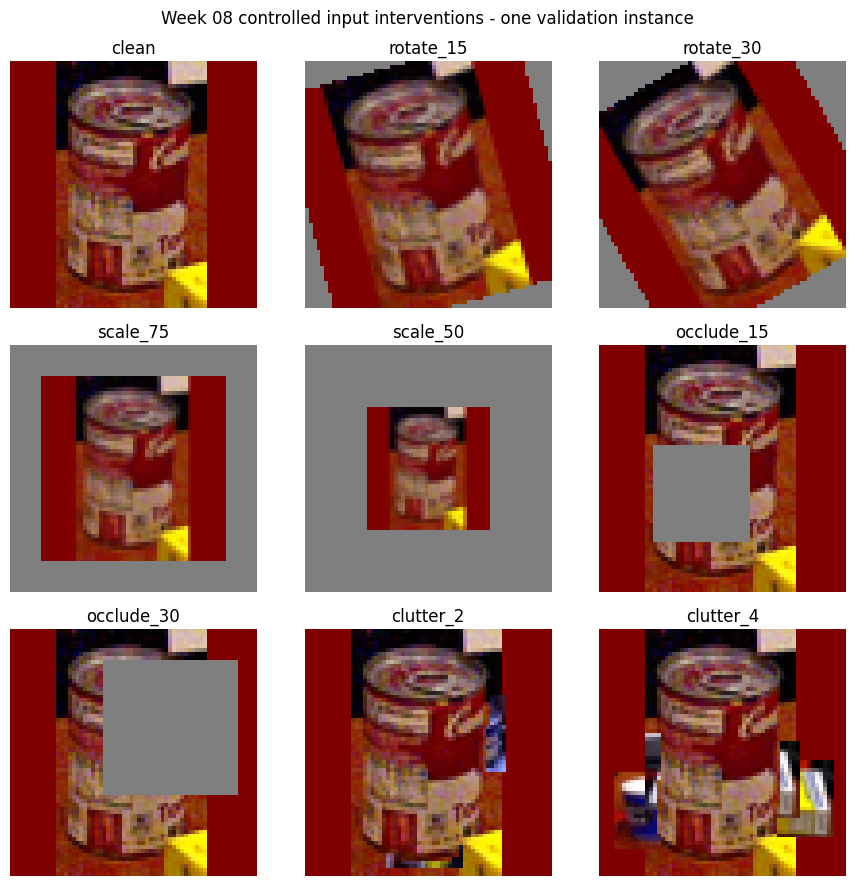

In [5]:
def crop_coordinates(row,padding=.08):
    with Image.open(row['rgb_path']) as im: W,H=im.size
    x,y,w,h=(int(row[k]) for k in ['x','y','w','h'])
    px,py=int(w*padding),int(h*padding)
    return (max(0,x-px),max(0,y-py),min(W,x+w+px),min(H,y+h+py))

def object_crop(row,padding=.08):
    with Image.open(row['rgb_path']) as im:
        return im.convert('RGB').crop(crop_coordinates(row,padding))

def letterbox(img,interpolation=Image.Resampling.BILINEAR,mode='RGB',fill=127):
    small=ImageOps.contain(img,(IMAGE_SIZE,IMAGE_SIZE),method=interpolation)
    canvas=Image.new(mode,(IMAGE_SIZE,IMAGE_SIZE),fill)
    canvas.paste(small,((IMAGE_SIZE-small.width)//2,(IMAGE_SIZE-small.height)//2))
    return canvas

def mask_on_letterbox(row):
    path=row['mask_path']
    if not path or not Path(path).exists():
        raise FileNotFoundError('BOP mask_visib required for controlled clutter: '+str(path))
    with Image.open(path) as raw:
        im=raw.convert('L').crop(crop_coordinates(row))
    return letterbox(im,interpolation=Image.Resampling.NEAREST,mode='L',fill=0)

def fixed_rng(row,variant):
    key=f"{row['scene_id']}:{row['im_id']}:{row['instance_idx']}:{variant}:{SEED}"
    return random.Random(int.from_bytes(hashlib.sha256(key.encode()).digest()[:8],'big'))

# Build distractor patches **from training images only**, one small crop per object class.
DISTRACTORS=[]
for oid in CLASS_IDS:
    for _,row in train_df[train_df.obj_id==oid].head(2).iterrows():
        DISTRACTORS.append((oid,object_crop(row).resize((20,20),Image.Resampling.BILINEAR)))

def perturb_image(base,row,variant):
    if variant=='clean': return base
    if variant.startswith('rotate_'):
        deg=int(variant.split('_')[1])
        return base.rotate(deg,resample=Image.Resampling.BILINEAR,fillcolor=(127,127,127))
    if variant.startswith('scale_'):
        factor=int(variant.split('_')[1])/100
        side=max(2,round(IMAGE_SIZE*factor))
        small=base.resize((side,side),Image.Resampling.BILINEAR)
        canvas=Image.new('RGB',(IMAGE_SIZE,IMAGE_SIZE),(127,127,127))
        canvas.paste(small,((IMAGE_SIZE-side)//2,(IMAGE_SIZE-side)//2))
        return canvas
    if variant.startswith('occlude_'):
        frac=int(variant.split('_')[1])/100
        rng=fixed_rng(row,variant)
        # Rectangle covers approximately `frac` of the 64x64 *canvas area*.
        side=max(3,min(IMAGE_SIZE,int(round(IMAGE_SIZE*math.sqrt(frac)))))
        cx=round(IMAGE_SIZE*(.35+.30*rng.random()))
        cy=round(IMAGE_SIZE*(.35+.30*rng.random()))
        x0=max(0,min(IMAGE_SIZE-side,cx-side//2));y0=max(0,min(IMAGE_SIZE-side,cy-side//2))
        out=base.copy();ImageDraw.Draw(out).rectangle((x0,y0,x0+side-1,y0+side-1),fill=(127,127,127))
        return out
    if variant.startswith('clutter_'):
        n=int(variant.split('_')[1])
        rng=fixed_rng(row,variant)
        out=base.copy()
        bank=[v for oid,v in DISTRACTORS if oid!=int(row['obj_id'])]
        for _ in range(n):
            patch=rng.choice(bank)
            x,y=rng.randrange(0,IMAGE_SIZE-20+1),rng.randrange(0,IMAGE_SIZE-20+1)
            out.paste(patch,(x,y))
        # Restore the original visible target: diagnostic changes only context.
        out.paste(base,(0,0),mask_on_letterbox(row))
        return out
    raise ValueError('Unknown scenario: '+variant)

SCENARIOS=['clean','rotate_15','rotate_30','scale_75','scale_50',
           'occlude_15','occlude_30','clutter_2','clutter_4']
NORMALIZERS={
    'compact':transforms.Compose([transforms.ToTensor(),
                                  transforms.Normalize([0.5]*3,[0.5]*3)]),
    'resnet18':transforms.Compose([transforms.ToTensor(),
                     transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])}

class CropDataset(Dataset):
    def __init__(self,frame,kind='compact',scenario='clean'):
        self.frame=frame.reset_index(drop=True)
        self.kind=kind;self.scenario=scenario
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        image=letterbox(object_crop(row))
        image=perturb_image(image,row,self.scenario)
        return NORMALIZERS[self.kind](image),CLASS_TO_INDEX[int(row.obj_id)]

def loader(frame,kind='compact',scenario='clean',shuffle=False):
    return DataLoader(CropDataset(frame,kind,scenario),batch_size=BATCH_SIZE,
        shuffle=shuffle,num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED) if shuffle else None)

# Small visual audit: same selected validation crop under all perturbations.
example=val_df.iloc[0]
fig,axs=plt.subplots(3,3,figsize=(9,9))
for ax,scenario in zip(axs.ravel(),SCENARIOS):
    ax.imshow(perturb_image(letterbox(object_crop(example)),example,scenario))
    ax.set_title(scenario);ax.axis('off')
fig.suptitle('Week 08 controlled input interventions - one validation instance')
plt.tight_layout();plt.savefig(OUT/'robustness_perturbation_examples.png',dpi=155);plt.show()

## 4. Models and **validation-only** checkpoint selection
CompactCNN reproduces Week 07's architecture, Adam loss and training schedule.
The stronger model starts from torchvision **ImageNet-pretrained ResNet18**:
3 head-only warm-up epochs, then at most 12 epochs fine-tuning `layer4 + fc`.
Lower ResNet layers are frozen. Model-specific ImageNet normalization is required
by the pretrained backbone. Architecture, pretraining, normalization and optimizer
therefore differ; this is an **end-to-end pipeline** comparison, not a single-factor
architecture ablation. Input crop geometry, split and training labels are fixed.

In [6]:
class CompactCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,96,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((4,4)))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(96*4*4,128),nn.ReLU(),
                                 nn.Dropout(0.30),nn.Linear(128,5))
    def forward(self,x):return self.head(self.features(x))

def make_pretrained_resnet():
    try:
        model=resnet18(weights=ResNet18_Weights.DEFAULT)
    except Exception as e:
        raise RuntimeError('Could not load ImageNet-pretrained ResNet18 weights. '
                           'Enable Colab network and retry; do NOT silently replace '
                           'with random weights.') from e
    model.fc=nn.Linear(model.fc.in_features,5)
    return model

def configure_resnet(model,phase):
    for p in model.parameters():p.requires_grad=False
    if phase=='warmup':
        for p in model.fc.parameters():p.requires_grad=True
        return torch.optim.AdamW(model.fc.parameters(),lr=1e-3,weight_decay=1e-4)
    if phase=='finetune':
        for p in model.layer4.parameters():p.requires_grad=True
        for p in model.fc.parameters():p.requires_grad=True
        return torch.optim.AdamW([{'params':model.layer4.parameters(),'lr':3e-5},
                                  {'params':model.fc.parameters(),'lr':3e-4}],weight_decay=1e-4)
    raise ValueError(phase)

def run_epoch(model,iterable,optimizer=None,resnet=False):
    training=optimizer is not None
    model.train(training)
    if training and resnet:
        # Keep frozen backbone BN statistics unchanged even during fine-tuning.
        for module in [model.conv1,model.bn1,model.layer1,model.layer2,model.layer3]:
            module.eval()
    loss_fn=nn.CrossEntropyLoss();total=correct=count=0
    for xb,yb in iterable:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(xb)
            loss=loss_fn(logits,yb)
            if training:loss.backward();optimizer.step()
        total+=float(loss.item())*len(yb)
        correct+=int((logits.argmax(1)==yb).sum().item())
        count+=len(yb)
    assert count
    return total/count,correct/count

def fit_model(model,kind,phases):
    best_loss=float('inf');best_epoch=None;best_state=None;global_epoch=0;history=[]
    start=time.time()
    for phase,n_epochs,optimizer,patience in phases:
        stale=0
        for _ in range(n_epochs):
            global_epoch+=1
            tl,ta=run_epoch(model,loader(train_df,kind,shuffle=True),optimizer,resnet=(kind=='resnet18'))
            vl,va=run_epoch(model,loader(val_df,kind),None,resnet=(kind=='resnet18'))
            history.append(dict(model=kind,phase=phase,epoch=global_epoch,
                                train_loss=tl,train_accuracy=ta,val_loss=vl,val_accuracy=va))
            print(f'{kind} {phase} epoch={global_epoch:02d} train_loss={tl:.4f} '
                  f'val_loss={vl:.4f} val_accuracy={va:.3f}')
            if vl<best_loss-1e-6:
                best_loss=vl;best_epoch=global_epoch;best_state=copy.deepcopy(model.state_dict());stale=0
            else:
                stale+=1
                if stale>=patience:
                    print(f'    Early stopping in {phase}');break
    assert best_state is not None
    model.load_state_dict(best_state)
    ckpt=CKPT/f'{kind}_best_validation_loss.pt'
    torch.save(best_state,ckpt)
    pd.DataFrame(history).to_csv(OUT/f'{kind}_training_history.csv',index=False)
    info=dict(model=kind,best_epoch=int(best_epoch),best_validation_loss=float(best_loss),
              seconds=time.time()-start,checkpoint=str(ckpt),
              parameter_count=sum(p.numel() for p in model.parameters()))
    (OUT/f'{kind}_training_meta.json').write_text(json.dumps(info,indent=2),encoding='utf8')
    return info

In [7]:
seed_everything()
compact=CompactCNN().to(DEVICE)
assert tuple(compact(torch.zeros(2,3,64,64,device=DEVICE)).shape)==(2,5)
compact_info=fit_model(compact,'compact',[
    ('from_scratch',15,torch.optim.Adam(compact.parameters(),lr=1e-3,weight_decay=1e-4),4)])
print('Retrained Week 07 baseline:',compact_info)

compact from_scratch epoch=01 train_loss=1.4292 val_loss=0.8948 val_accuracy=0.755
compact from_scratch epoch=02 train_loss=0.3433 val_loss=0.1035 val_accuracy=0.960
compact from_scratch epoch=03 train_loss=0.0309 val_loss=0.0051 val_accuracy=1.000
compact from_scratch epoch=04 train_loss=0.0169 val_loss=0.0344 val_accuracy=0.989
compact from_scratch epoch=05 train_loss=0.0185 val_loss=0.0010 val_accuracy=1.000
compact from_scratch epoch=06 train_loss=0.0054 val_loss=0.0356 val_accuracy=0.989
compact from_scratch epoch=07 train_loss=0.0029 val_loss=0.0042 val_accuracy=1.000
compact from_scratch epoch=08 train_loss=0.0013 val_loss=0.0219 val_accuracy=0.995
compact from_scratch epoch=09 train_loss=0.0029 val_loss=0.0078 val_accuracy=0.997
    Early stopping in from_scratch
Retrained Week 07 baseline: {'model': 'compact', 'best_epoch': 5, 'best_validation_loss': 0.0009522228228549162, 'seconds': 243.5815508365631, 'checkpoint': 'outputs/week08/checkpoints/compact_best_validation_loss.pt',

In [8]:
seed_everything()
strong=make_pretrained_resnet().to(DEVICE)
assert tuple(strong.eval()(torch.zeros(2,3,64,64,device=DEVICE)).shape)==(2,5)
head_optimizer=configure_resnet(strong,'warmup')
# Fit across TWO STAGES in one function so selection remains based on min val loss.
# Configure the fine-tuning optimizer immediately before the later stage: the
# function below calls configure_resnet inside the stage loop, never beforehand.
def train_resnet_two_stage(model):
    best_loss=float('inf');best_state=None;best_epoch=None;history=[];epoch=0
    start=time.time()
    for phase,limit,patience in [('warmup',3,3),('finetune',12,4)]:
        optimizer=configure_resnet(model,phase)
        stale=0
        for _ in range(limit):
            epoch+=1
            tr_l,tr_a=run_epoch(model,loader(train_df,'resnet18',shuffle=True),optimizer,True)
            val_l,val_a=run_epoch(model,loader(val_df,'resnet18'),None,True)
            history.append(dict(model='resnet18',phase=phase,epoch=epoch,
                        train_loss=tr_l,train_accuracy=tr_a,val_loss=val_l,val_accuracy=val_a))
            print(f'ResNet18 {phase} epoch={epoch:02d}: val_loss={val_l:.4f} val_acc={val_a:.4f}')
            if val_l<best_loss-1e-6:
                best_loss=val_l;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());stale=0
            else:
                stale+=1
                if stale>=patience:
                    print('    Stopped after validation plateau');break
    assert best_state is not None
    model.load_state_dict(best_state)
    ckpt=CKPT/'resnet18_best_validation_loss.pt'
    torch.save(best_state,ckpt)
    pd.DataFrame(history).to_csv(OUT/'resnet18_training_history.csv',index=False)
    info=dict(model='resnet18',best_epoch=int(best_epoch),best_validation_loss=float(best_loss),
              seconds=time.time()-start,checkpoint=str(ckpt),
              parameter_count=sum(p.numel() for p in model.parameters()),
              pretrained_weights='ResNet18_Weights.DEFAULT (ImageNet)')
    (OUT/'resnet18_training_meta.json').write_text(json.dumps(info,indent=2),encoding='utf8')
    return info
strong_info=train_resnet_two_stage(strong)
print('Transfer-learning system:',strong_info)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


ResNet18 warmup epoch=01: val_loss=0.7502 val_acc=0.8213
ResNet18 warmup epoch=02: val_loss=0.7008 val_acc=0.8400
ResNet18 warmup epoch=03: val_loss=0.6634 val_acc=0.8160
ResNet18 finetune epoch=04: val_loss=0.3353 val_acc=0.9680
ResNet18 finetune epoch=05: val_loss=0.2429 val_acc=0.9787
ResNet18 finetune epoch=06: val_loss=0.2157 val_acc=0.9787
ResNet18 finetune epoch=07: val_loss=0.2049 val_acc=0.9787
ResNet18 finetune epoch=08: val_loss=0.1988 val_acc=0.9787
ResNet18 finetune epoch=09: val_loss=0.1943 val_acc=0.9787
ResNet18 finetune epoch=10: val_loss=0.1903 val_acc=0.9787
ResNet18 finetune epoch=11: val_loss=0.1867 val_acc=0.9787
ResNet18 finetune epoch=12: val_loss=0.1833 val_acc=0.9813
ResNet18 finetune epoch=13: val_loss=0.1801 val_acc=0.9813
ResNet18 finetune epoch=14: val_loss=0.1770 val_acc=0.9813
ResNet18 finetune epoch=15: val_loss=0.1741 val_acc=0.9813
Transfer-learning system: {'model': 'resnet18', 'best_epoch': 15, 'best_validation_loss': 0.17414108363787334, 'seconds':

## 5. Validation comparison, per-class metrics and training curves
We freeze checkpoints based **only on validation loss**. Robustness results below
are post-hoc diagnostics; do NOT tune settings after viewing them.

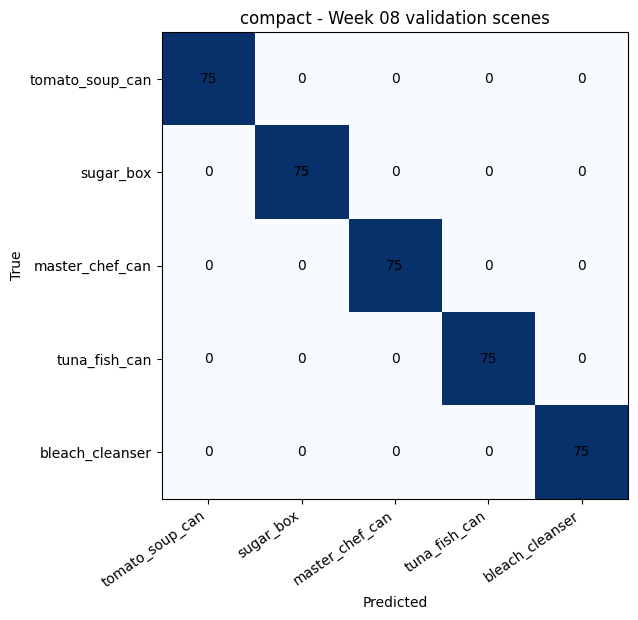

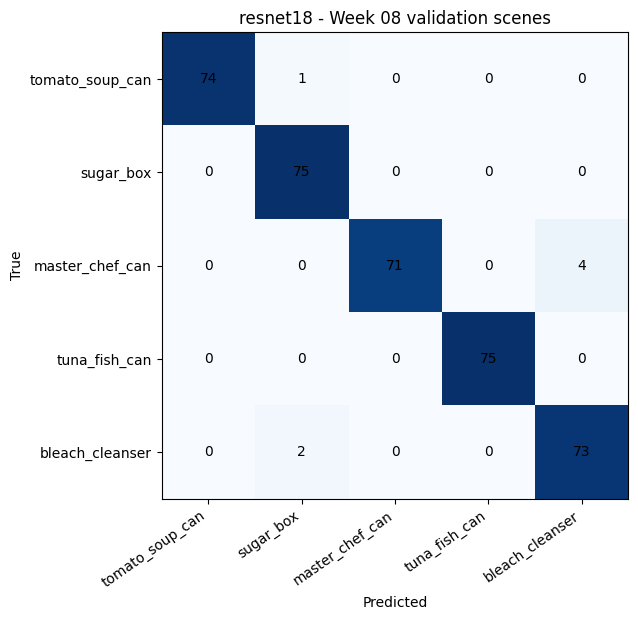

Clean validation comparison:


,model,n,accuracy,macro_f1,errors,master_recall
0,compact,375,1.000000,1.000000,0,1.000000
1,resnet18,375,0.981333,0.981362,7,0.946667


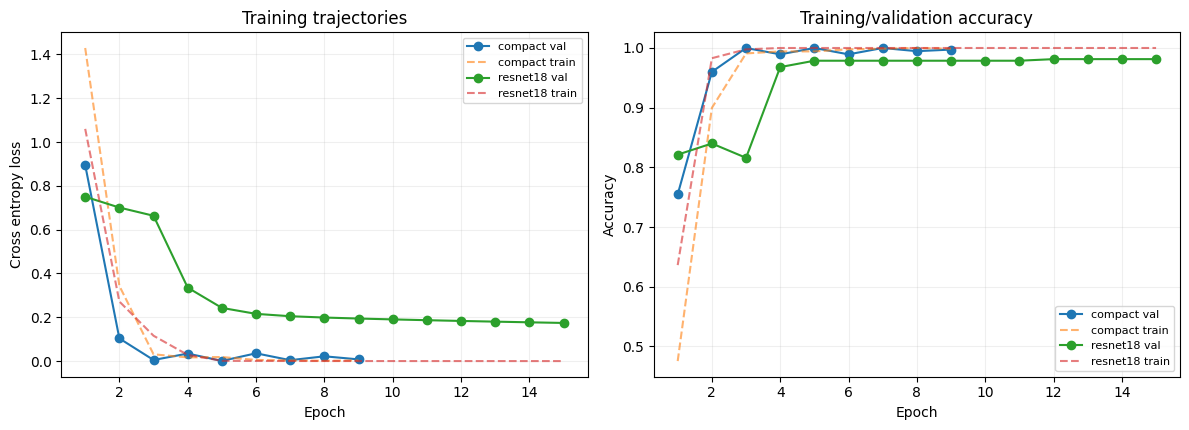

In [9]:
@torch.no_grad()
def predict(model,frame,kind,scenario='clean',split='validation'):
    model.eval();preds=[];pos=0
    for xb,yb in loader(frame,kind,scenario):
        prob=torch.softmax(model(xb.to(DEVICE)),dim=1).cpu().numpy()
        pred=np.argmax(prob,axis=1)
        for j in range(len(yb)):
            row=frame.iloc[pos+j]
            preds.append(dict(split=split,model=kind,scenario=scenario,
                  scene_id=int(row.scene_id),im_id=int(row.im_id),
                  instance_idx=int(row.instance_idx),obj_id=int(row.obj_id),
                  true_index=int(yb[j]),pred_index=int(pred[j]),
                  true_class=CLASSES[int(yb[j])],pred_class=CLASSES[int(pred[j])],
                  confidence=float(prob[j].max()),correct=int(pred[j]==int(yb[j])),
                  visib_fract=float(row.visib_fract),nearby_count=int(row.nearby_count),
                  bbox_sqrt_area=float(row.bbox_sqrt_area),
                  view_x=float(row.view_x),view_y=float(row.view_y),view_z=float(row.view_z)))
        pos+=len(yb)
    assert pos==len(frame)
    return pd.DataFrame(preds)

def metrics(df):
    y,p=df.true_index,df.pred_index
    return dict(n=int(len(df)),accuracy=float(accuracy_score(y,p)),
                macro_f1=float(f1_score(y,p,average='macro',labels=range(5),zero_division=0)),
                errors=int((y!=p).sum()),
                master_recall=float(((df.true_index==2)&(df.pred_index==2)).sum()/max(1,(df.true_index==2).sum())))

def save_classwise(df,filename):
    p,r,f,s=precision_recall_fscore_support(df.true_index,df.pred_index,
                               labels=range(5),zero_division=0)
    table=pd.DataFrame(dict(class_name=CLASSES,support=s,precision=p,recall=r,f1=f))
    table.to_csv(OUT/filename,index=False)
    return table

def save_confusion(df,filename,title):
    cm=confusion_matrix(df.true_index,df.pred_index,labels=range(5))
    pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(OUT/filename.replace('.png','.csv'))
    fig,ax=plt.subplots(figsize=(8.4,6.3))
    ax.imshow(cm,cmap='Blues');ax.set_xticks(range(5),CLASSES,rotation=35,ha='right')
    ax.set_yticks(range(5),CLASSES);ax.set_xlabel('Predicted');ax.set_ylabel('True')
    for i in range(5):
        for j in range(5):ax.text(j,i,int(cm[i,j]),ha='center',va='center')
    ax.set_title(title);plt.tight_layout();plt.savefig(OUT/filename,dpi=160,bbox_inches='tight');plt.show()

VALIDATION={}
for kind,model in [('compact',compact),('resnet18',strong)]:
    table=predict(model,val_df,kind)
    VALIDATION[kind]=table
    table.to_csv(OUT/f'{kind}_validation_predictions.csv',index=False)
    save_classwise(table,f'{kind}_validation_classwise.csv')
    save_confusion(table,f'{kind}_validation_confusion.png',f'{kind} - Week 08 validation scenes')
validation_summary=pd.DataFrame([dict(model=kind,**metrics(df)) for kind,df in VALIDATION.items()])
validation_summary.to_csv(OUT/'validation_comparison.csv',index=False)
print('Clean validation comparison:')
display(validation_summary)

fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for kind in ['compact','resnet18']:
    hist=pd.read_csv(OUT/f'{kind}_training_history.csv')
    axs[0].plot(hist.epoch,hist.val_loss,marker='o',label=kind+' val')
    axs[0].plot(hist.epoch,hist.train_loss,alpha=.6,ls='--',label=kind+' train')
    axs[1].plot(hist.epoch,hist.val_accuracy,marker='o',label=kind+' val')
    axs[1].plot(hist.epoch,hist.train_accuracy,alpha=.6,ls='--',label=kind+' train')
axs[0].set(xlabel='Epoch',ylabel='Cross entropy loss',title='Training trajectories')
axs[1].set(xlabel='Epoch',ylabel='Accuracy',title='Training/validation accuracy')
for ax in axs:ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'training_curves.png',dpi=165,bbox_inches='tight');plt.show()

## 6. Paired synthetic robustness on validation only
Every perturbation is deterministic for each `(scene_id, im_id, instance_idx)`.
Both models receive exactly the same RGB pixels per scenario (but different
normalizations appropriate to their training). Accuracy drops are computed
relative to each model's OWN clean validation baseline.

compact  clean        acc=1.0000 macro-F1=1.0000 delta=+0.00 pp
compact  rotate_15    acc=0.9893 macro-F1=0.9893 delta=-1.07 pp
compact  rotate_30    acc=0.6320 macro-F1=0.5699 delta=-36.80 pp
compact  scale_75     acc=0.7653 macro-F1=0.7350 delta=-23.47 pp
compact  scale_50     acc=0.4000 macro-F1=0.2700 delta=-60.00 pp
compact  occlude_15   acc=0.9707 macro-F1=0.9706 delta=-2.93 pp
compact  occlude_30   acc=0.9013 macro-F1=0.9027 delta=-9.87 pp
compact  clutter_2    acc=0.9733 macro-F1=0.9733 delta=-2.67 pp
compact  clutter_4    acc=0.8987 macro-F1=0.8947 delta=-10.13 pp
resnet18 clean        acc=0.9813 macro-F1=0.9814 delta=+0.00 pp
resnet18 rotate_15    acc=0.6293 macro-F1=0.6035 delta=-35.20 pp
resnet18 rotate_30    acc=0.5280 macro-F1=0.4650 delta=-45.33 pp
resnet18 scale_75     acc=0.2187 macro-F1=0.1019 delta=-76.27 pp
resnet18 scale_50     acc=0.2000 macro-F1=0.0667 delta=-78.13 pp
resnet18 occlude_15   acc=0.7733 macro-F1=0.7732 delta=-20.80 pp
resnet18 occlude_30   acc=0.514

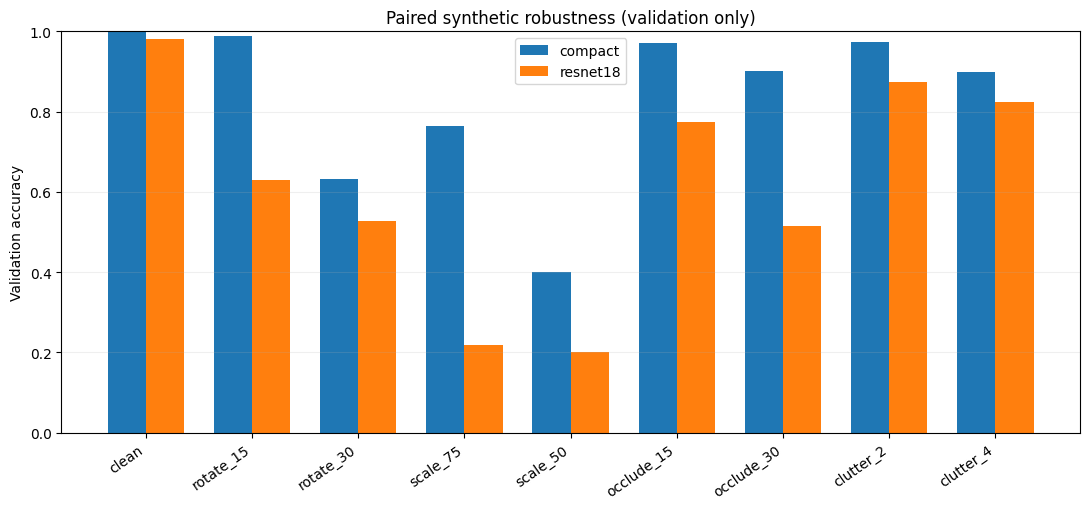

In [10]:
robust_predictions=[];robust_results=[]
for kind,model in [('compact',compact),('resnet18',strong)]:
    clean_acc=metrics(VALIDATION[kind])['accuracy']
    for scenario in SCENARIOS:
        preds=VALIDATION[kind].copy() if scenario=='clean' else predict(model,val_df,kind,scenario)
        robust_predictions.append(preds)
        row=dict(model=kind,scenario=scenario,**metrics(preds))
        row['delta_accuracy_pp']=100*(row['accuracy']-clean_acc)
        robust_results.append(row)
        print(f'{kind:8s} {scenario:11s}  acc={row["accuracy"]:.4f} '
              f'macro-F1={row["macro_f1"]:.4f} delta={row["delta_accuracy_pp"]:+.2f} pp')
robust_predictions=pd.concat(robust_predictions,ignore_index=True)
robust_predictions.to_csv(OUT/'robustness_validation_predictions.csv',index=False)
robust_summary=pd.DataFrame(robust_results)
robust_summary.to_csv(OUT/'robustness_validation_summary.csv',index=False)

fig,ax=plt.subplots(figsize=(11,5.2))
positions=np.arange(len(SCENARIOS));width=.36
for k,(kind,g) in enumerate(robust_summary.groupby('model',sort=False)):
    g=g.set_index('scenario').loc[SCENARIOS]
    ax.bar(positions+width*(k-.5),g.accuracy.to_numpy(),width,label=kind)
ax.set_xticks(positions,SCENARIOS,rotation=35,ha='right')
ax.set(ylim=(0,1),ylabel='Validation accuracy',title='Paired synthetic robustness (validation only)')
ax.legend();ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'robustness_validation_comparison.png',dpi=165,bbox_inches='tight');plt.show()

## 7. Real BOP viewpoint/scale/visibility/clutter strata
- Viewpoint: angle between the example's **3D camera-position direction in object
  coordinates** and the nearest training example's direction for the same class.
  This measures novelty to training views; it does NOT measure an intervention.
- Scale: square root of BOP `bbox_obj` area; train-set 33/66% thresholds.
- Visibility: annotated `visib_fract` in [0.35,1].
- Clutter: number of other BOP annotated object boxes intersecting an expanded
  2x target rectangle; this is a *proxy* for nearby annotated scene objects.
Beware rotational symmetries (especially cans), bins with small n and scene
confounding. Stratification is descriptive, not causal.

Natural strata - interpret groups with low support cautiously:


,model,factor,group,n,accuracy,macro_f1,errors,master_recall
0,compact,view_bin,0-15,229,1.000000,1.000000,0,1.000000
1,compact,view_bin,15-30,98,1.000000,0.800000,0,1.000000
2,compact,view_bin,30-60,48,1.000000,0.600000,0,1.000000
3,compact,scale_bin,medium,215,1.000000,0.600000,0,1.000000
4,compact,scale_bin,small,160,1.000000,0.600000,0,0.000000
5,compact,visibility_bin,0.50-0.75,110,1.000000,0.400000,0,0.000000
6,compact,visibility_bin,0.75-1.00,265,1.000000,1.000000,0,1.000000
7,compact,clutter_bin,1 nearby,30,1.000000,0.200000,0,0.000000
8,compact,clutter_bin,2+ nearby,345,1.000000,1.000000,0,1.000000
9,resnet18,view_bin,0-15,229,0.991266,0.989961,2,1.000000


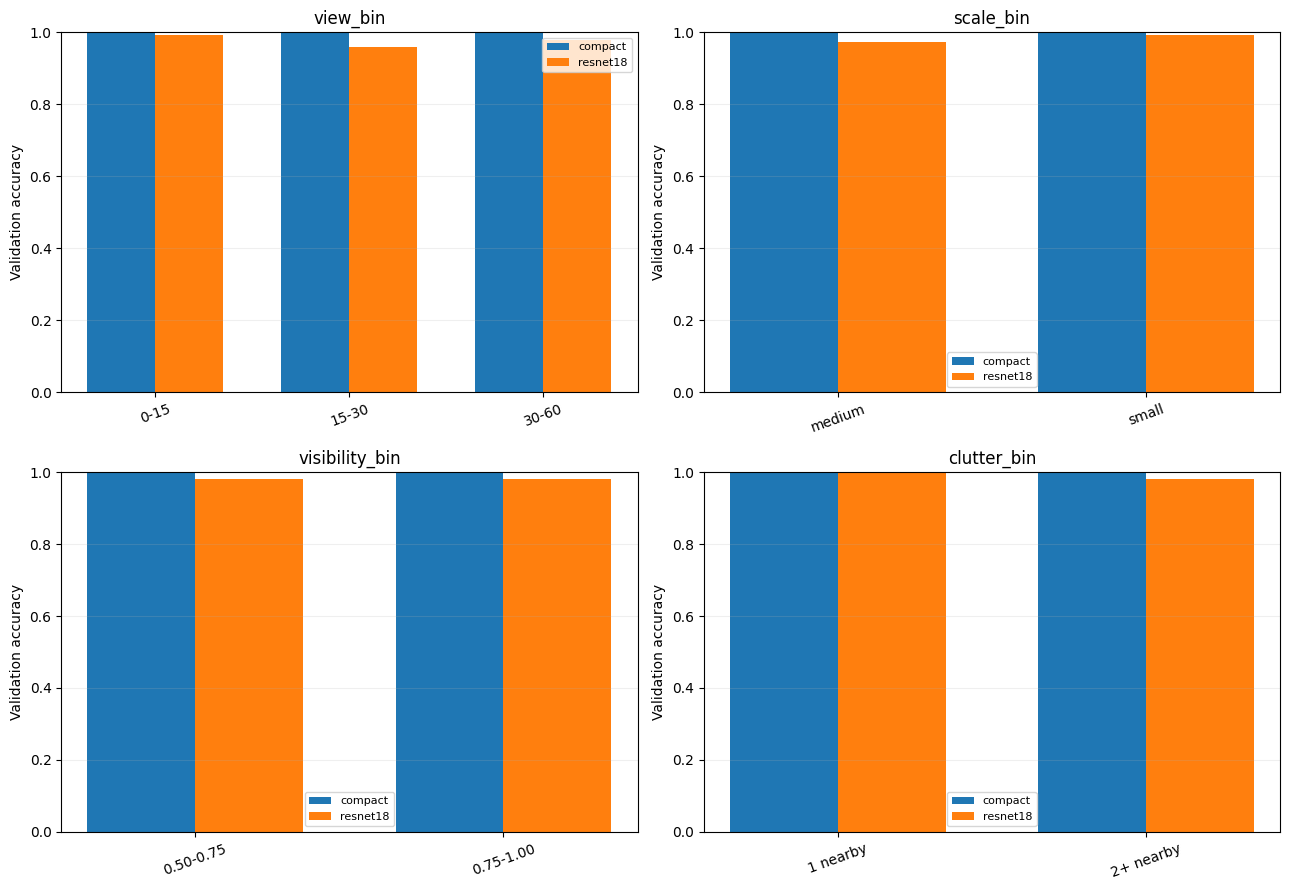

In [11]:
TRAIN_VIEW_BANK={}
for obj_id,g in train_df.groupby('obj_id'):
    bank=g[['view_x','view_y','view_z']].to_numpy(dtype=float)
    TRAIN_VIEW_BANK[int(obj_id)]=bank[np.isfinite(bank).all(axis=1)]
train_q1,train_q2=np.quantile(train_df.bbox_sqrt_area,[1/3,2/3])

def angle_to_nearest_training_view(row):
    v=np.array([row.view_x,row.view_y,row.view_z],dtype=float)
    bank=TRAIN_VIEW_BANK[int(row.obj_id)]
    if not np.isfinite(v).all() or len(bank)==0:return np.nan
    dots=np.clip(bank@v,-1,1)
    return float(np.degrees(np.arccos(float(dots.max()))))

natural_frame=val_df.copy()
natural_frame['novel_view_degrees']=natural_frame.apply(angle_to_nearest_training_view,axis=1)
natural_frame['view_bin']=pd.cut(natural_frame.novel_view_degrees,
                     [-1,15,30,60,181],labels=['0-15','15-30','30-60','60+']).astype(str)
natural_frame['scale_bin']=pd.cut(natural_frame.bbox_sqrt_area,
                  [-np.inf,train_q1,train_q2,np.inf],labels=['small','medium','large']).astype(str)
natural_frame['visibility_bin']=pd.cut(natural_frame.visib_fract,
                  [0.349,0.5,0.75,1.00001],labels=['0.35-0.50','0.50-0.75','0.75-1.00'],
                  include_lowest=True).astype(str)
natural_frame['clutter_bin']=pd.cut(natural_frame.nearby_count,
                      [-1,0,1,np.inf],labels=['0 nearby','1 nearby','2+ nearby']).astype(str)
natural_frame.to_csv(OUT/'validation_natural_strata.csv',index=False)

identity=['scene_id','im_id','instance_idx']
strata=[]
for kind,df in VALIDATION.items():
    merged=df.merge(natural_frame[identity+['view_bin','scale_bin','visibility_bin','clutter_bin',
                        'novel_view_degrees']],on=identity,validate='one_to_one')
    for col in ['view_bin','scale_bin','visibility_bin','clutter_bin']:
        for label,chunk in merged.groupby(col,sort=True):
            record=dict(model=kind,factor=col,group=str(label),**metrics(chunk))
            strata.append(record)
strata_summary=pd.DataFrame(strata)
strata_summary.to_csv(OUT/'natural_validation_strata_summary.csv',index=False)
print('Natural strata - interpret groups with low support cautiously:')
display(strata_summary)

fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,col in zip(axs.flat,['view_bin','scale_bin','visibility_bin','clutter_bin']):
    d=strata_summary[strata_summary.factor==col]
    groups=list(dict.fromkeys(d.group))
    ix=np.arange(len(groups))
    for k,kind in enumerate(['compact','resnet18']):
        vals=[d[(d.model==kind)&(d.group==s)].accuracy.iloc[0]
              if len(d[(d.model==kind)&(d.group==s)]) else np.nan for s in groups]
        ax.bar(ix+(k-.5)*.35,vals,.35,label=kind)
    ax.set_xticks(ix,groups,rotation=20)
    ax.set_ylim(0,1);ax.set_ylabel('Validation accuracy');ax.set_title(col)
    ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'natural_validation_strata.png',dpi=165,bbox_inches='tight');plt.show()

## 8. Error transitions and diverse qualitative examples (validation)
Prioritize `master_chef_can -> tomato_soup_can` and
`bleach_cleanser -> tomato_soup_can`; the strong model's error mechanisms may differ.
Use multiple classes/scenes instead of the first eight near-duplicate frames.

,true_class,pred_class,count,model
0,master_chef_can,bleach_cleanser,4,resnet18
1,bleach_cleanser,sugar_box,2,resnet18
2,tomato_soup_can,sugar_box,1,resnet18


compact : no validation errors


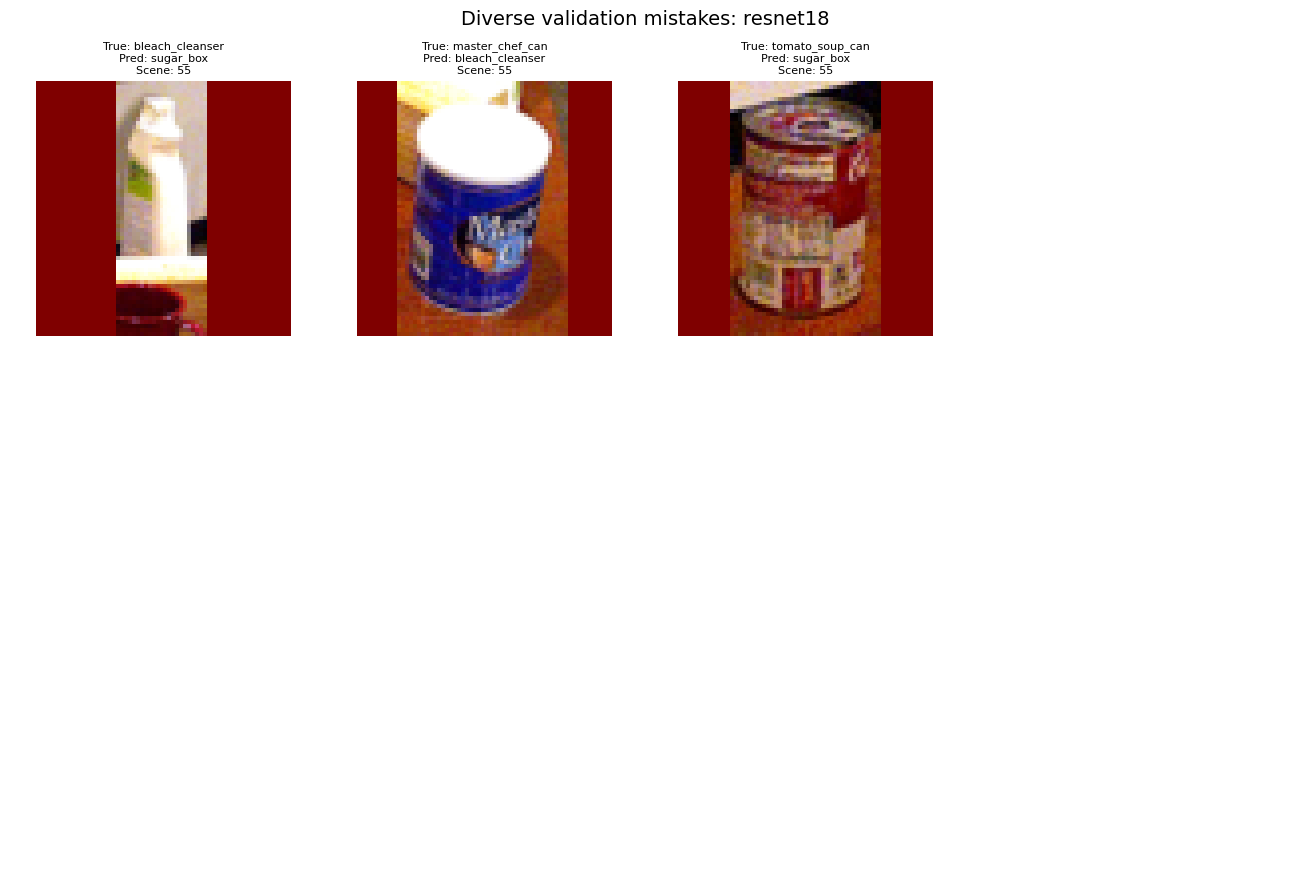

In [12]:
error_transitions=[]
for kind,df in VALIDATION.items():
    t=(df[df.correct==0].groupby(['true_class','pred_class'])
       .size().rename('count').reset_index().sort_values('count',ascending=False))
    t['model']=kind
    error_transitions.append(t)
error_transitions=pd.concat(error_transitions,ignore_index=True)
error_transitions.to_csv(OUT/'validation_error_transitions.csv',index=False)
display(error_transitions.head(15))

def gallery_for(kind):
    preds=VALIDATION[kind]
    wrong=preds[preds.correct==0].sort_values(['true_class','pred_class','scene_id','im_id'])
    if len(wrong)==0:
        print(kind,': no validation errors');return
    selection=wrong.drop_duplicates(['true_class','pred_class','scene_id']).head(12)
    selected=selection.merge(val_df,on=identity,validate='one_to_one',suffixes=('','_meta'))
    fig,axs=plt.subplots(3,4,figsize=(13,9))
    for ax in axs.flat:ax.axis('off')
    for ax,(_,row) in zip(axs.flat,selected.iterrows()):
        ax.imshow(letterbox(object_crop(row)))
        ax.set_title(f"True: {row.true_class}\nPred: {row.pred_class}\nScene: {row.scene_id}",fontsize=8)
        ax.axis('off')
    fig.suptitle(f'Diverse validation mistakes: {kind}',fontsize=14)
    plt.tight_layout();plt.savefig(OUT/f'{kind}_validation_errors.png',dpi=155,bbox_inches='tight');plt.show()
for kind in ['compact','resnet18']:gallery_for(kind)

## 9. **One-time test gate** after the complete protocol is frozen
Both Week 08 models are evaluated on the *same* original scenes 51 and 59.
Since Week 07 test results are already known, these scenes do not represent
new project-wide unseen data; report this limitation explicitly.

This gate **REFUSES repeated inference** if a result file exists. After a
successful run, download/retain `outputs/week08` to avoid accidental re-tests.
Changing any settings after seeing test outcomes would invalidate a clean
model-comparison claim. `RUN_FINAL_TEST=False` skips this part altogether.

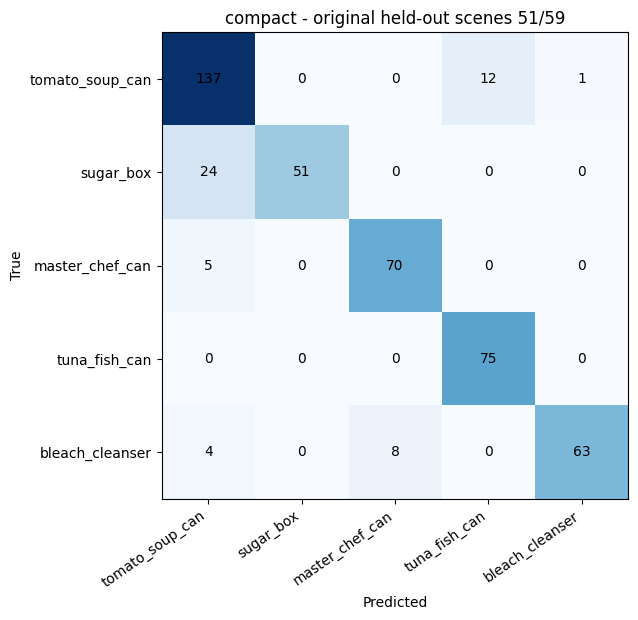

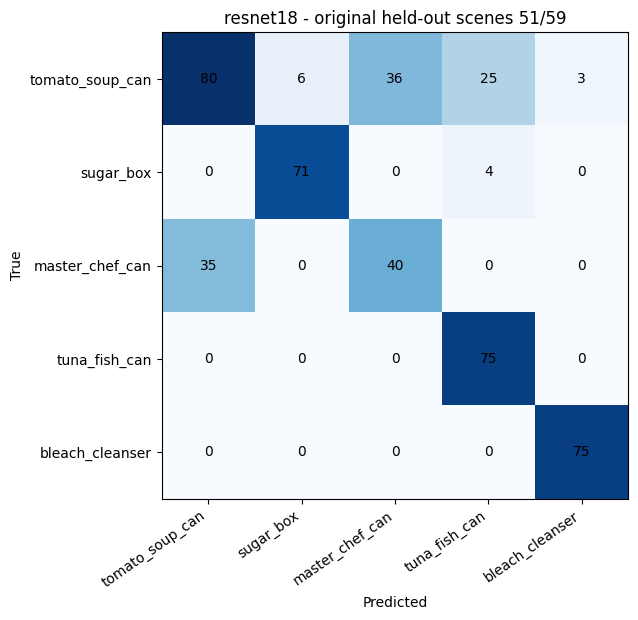

FINAL TEST RECORDED (same scenes known from Week 07):


,model,n,accuracy,macro_f1,errors,master_recall
0,compact,450,0.880000,0.882641,54,0.933333
1,resnet18,450,0.757778,0.777233,109,0.533333


In [13]:
FINAL_TEST_FILE=OUT/'week08_final_test_summary.json'
def sha256_file(path):
    digest=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            digest.update(block)
    return digest.hexdigest()
checkpoint_hashes={kind:sha256_file(CKPT/f'{kind}_best_validation_loss.pt')
                   for kind in ['compact','resnet18']}
TEST_SUMMARY=[]
if RUN_FINAL_TEST:
    if FINAL_TEST_FILE.exists():
        print('Existing FINAL test already recorded; reusing saved results only (no inference).')
        saved=json.loads(FINAL_TEST_FILE.read_text(encoding='utf8'))
        if saved.get('checkpoint_sha256')!=checkpoint_hashes:
            raise RuntimeError('Already-tested checkpoint differs from current model weights. '
                'Do not mix old test metrics with new checkpoints. Stop and preserve prior outputs.')
        TEST_SUMMARY=saved['results']
        for kind in ['compact','resnet18']:
            if not (OUT/f'{kind}_test_predictions.csv').exists():
                raise RuntimeError('Final test JSON exists but its prediction CSV is missing: preserve the run atomically.')
    else:
        # Re-load exactly the checkpoint selected by minimum validation loss.
        compact.load_state_dict(torch.load(CKPT/'compact_best_validation_loss.pt',map_location=DEVICE,weights_only=True))
        strong.load_state_dict(torch.load(CKPT/'resnet18_best_validation_loss.pt',map_location=DEVICE,weights_only=True))
        for kind,model in [('compact',compact),('resnet18',strong)]:
            df=predict(model,test_df,kind,scenario='clean',split='test')
            df.to_csv(OUT/f'{kind}_test_predictions.csv',index=False)
            save_classwise(df,f'{kind}_test_classwise.csv')
            save_confusion(df,f'{kind}_test_confusion.png',f'{kind} - original held-out scenes 51/59')
            result=dict(model=kind,**metrics(df))
            TEST_SUMMARY.append(result)
        FINAL_TEST_FILE.write_text(json.dumps(dict(
            run_utc=datetime.now(timezone.utc).isoformat(),
            caveat='Same scenes were previously exposed during Week 07; not a new blind external set.',
            historical_week07=dict(test_accuracy=327/450,test_macro_f1=0.713181),
            checkpoint_sha256=checkpoint_hashes,
            results=TEST_SUMMARY),indent=2),encoding='utf8')
    print('FINAL TEST RECORDED (same scenes known from Week 07):')
    display(pd.DataFrame(TEST_SUMMARY))
else:
    print('Final test deliberately skipped. Results are validation-only.')

## 10. Produce the completed report and downloadable ZIP
This report is built **AFTER** the training/evaluation cells; every Week 08
number comes from measured CSV/JSON outputs. If final test was skipped the
generated document is labeled `VALIDATION ONLY`, not `final held-out`.

In [14]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (SimpleDocTemplate,Paragraph,Spacer,Table,TableStyle,
                               Image as RLImage,PageBreak,KeepTogether)
from docx import Document
from docx.shared import Inches,Pt

val_comp=pd.read_csv(OUT/'validation_comparison.csv')
rob_comp=pd.read_csv(OUT/'robustness_validation_summary.csv')
nat_comp=pd.read_csv(OUT/'natural_validation_strata_summary.csv')
week08_test=pd.DataFrame(TEST_SUMMARY)
final_status='EXECUTED (historical test scenes)' if RUN_FINAL_TEST else 'VALIDATION ONLY'

styles=getSampleStyleSheet()
styles.add(ParagraphStyle(name='W8Title',parent=styles['Heading1'],fontSize=18,leading=22,
                          textColor=colors.HexColor('#1c3957'),spaceAfter=12))
styles.add(ParagraphStyle(name='W8Body',parent=styles['BodyText'],fontSize=9.2,leading=14,spaceAfter=6))
styles.add(ParagraphStyle(name='W8Small',parent=styles['BodyText'],fontSize=8.1,leading=11,spaceAfter=5))

# Data shared between DOCX and PDF sections - no assumed Week 08 results.
old_acc=327/450
old_f1=.713181
c_val=val_comp[val_comp.model=='compact'].iloc[0]
r_val=val_comp[val_comp.model=='resnet18'].iloc[0]
val_delta_acc=100*(r_val.accuracy-c_val.accuracy)
val_delta_f1=r_val.macro_f1-c_val.macro_f1
worst=[]
for kind,g in rob_comp.groupby('model'):
    d=g[g.scenario!='clean'].sort_values('delta_accuracy_pp').iloc[0]
    worst.append(f"{kind}: {d.scenario} ({d.delta_accuracy_pp:+.2f} pp vs clean validation)")
comparison_rows=[['System','Clean val accuracy','Clean val macro-F1'],
                 ['CompactCNN rerun',f'{c_val.accuracy:.4f}',f'{c_val.macro_f1:.4f}'],
                 ['ImageNet ResNet18',f'{r_val.accuracy:.4f}',f'{r_val.macro_f1:.4f}']]
if not week08_test.empty:
    for _,r in week08_test.iterrows():
        comparison_rows.append([f'{r.model} final test',f'{r.accuracy:.4f}',f'{r.macro_f1:.4f}'])

report_path=OUT/'Week_08_Technical_Report_EXECUTED.pdf'
story=[]
def para(text,style='W8Body'):story.append(Paragraph(text,styles[style]))
def heading(text):para(text,'Heading2')
def pic(name,maxw=17*cm,maxh=13*cm):
    path=OUT/name
    if not path.exists():return
    with Image.open(path) as im:w,h=im.size
    sc=min(maxw/w,maxh/h)
    story.append(RLImage(str(path),width=w*sc,height=h*sc))
    story.append(Spacer(1,8))
def tab(rows,widths=None):
    t=Table([[str(x) for x in row] for row in rows],colWidths=widths,repeatRows=1,hAlign='LEFT')
    t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#e8eff7')),
        ('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.white,colors.HexColor('#f8fafc')]),
        ('LINEBELOW',(0,0),(-1,0),.6,colors.HexColor('#9fb2c5')),
        ('BOTTOMPADDING',(0,0),(-1,-1),6),('TOPPADDING',(0,0),(-1,-1),6),
        ('FONTNAME',(0,0),(-1,0),'Helvetica-Bold'),('FONTSIZE',(0,0),(-1,-1),8),
        ('VALIGN',(0,0),(-1,-1),'TOP')]))
    story.append(t);story.append(Spacer(1,12))

para('WEEK 08 | CNN CLASSIFICATION II','W8Title')
para(f'<b>Intern:</b> Mehrana Rezaei | <b>Group:</b> 1 | <b>Status:</b> {final_status}')
heading('1. Objective and evidence')
para('Continue Week 07 YCB-V BOP19 five-class cropped-object classification. Compare the '
     'retrained CompactCNN to ImageNet-pretrained ResNet18 while preserving 8%-padded 64x64 '
     'letterbox crops and the exact scene-disjoint split (877/375/450).')
para(f'Historical Week 07: held-out accuracy {old_acc:.4f}; macro-F1 {old_f1:.4f}; '
     'master_chef_can recall 0.2400 (57 master to tomato confusions). This ZIP contained '
     'an executed notebook and PDF, but NOT a model checkpoint. The Week 08 CompactCNN '
     'is therefore a newly trained replication, not the identical saved Week 07 model.')
heading('2. Training design and clean validation')
para('CompactCNN: three convolution blocks 32/64/96, pooling, dropout 0.30, Adam 1e-3, '
     'weight decay 1e-4, 15 epochs maximum and patience 4. ResNet18: torchvision '
     'ImageNet DEFAULT weights, new five-class head, 3 head-only epochs and up to 12 '
     'epochs of final-block + head fine-tuning (AdamW 3e-5/3e-4, respectively). '
     'Each checkpoint was chosen only by minimum validation cross entropy.')
tab(comparison_rows,[6.5*cm,5.1*cm,5.1*cm])
para(f'Validation difference (ResNet18 minus retrained CompactCNN): '
     f'{val_delta_acc:+.2f} percentage points accuracy; {val_delta_f1:+.4f} macro-F1.')
pic('training_curves.png')
heading('3. Synthetic robustness (validation only)')
para('Paired deterministic interventions: 15/30 degree in-plane rotation (2D proxy, NOT '
     'novel 3D viewpoint), 75%/50% downscaling, 15%/30% gray-canvas patch area, '
     'and 2/4 pasted non-target distractor patches with original visible foreground '
     'restored from BOP mask_visib. Perturbations are diagnostic, not training augmentation.')
pic('robustness_validation_comparison.png')
para('Largest accuracy degradations: '+'; '.join(worst)+'.')
heading('4. BOP-annotation robustness strata')
para('3D viewpoint novelty = minimum angular difference between the camera-position '
     'direction (in object coordinates) and same-class training examples; measured '
     'using cam_R_m2c and cam_t_m2c. Scale = square-root bbox area (train tertiles). '
     'Visibility = visib_fract. Clutter = number of nearby annotated boxes intersecting '
     'a double-size rectangle. These are observational associations, not causal estimates. '
     'Rotationally symmetric objects and small bins can distort interpretation.')
pic('natural_validation_strata.png')
heading('5. Failure analysis')
trans=pd.read_csv(OUT/'validation_error_transitions.csv')
for kind in ['compact','resnet18']:
    top=trans[trans.model==kind].nlargest(3,'count')
    pairs='; '.join(f'{t.true_class} to {t.pred_class}: {int(t["count"])}' for _,t in top.iterrows())
    para(f'<b>{kind} top validation confusions:</b> '+(pairs or 'none'))
pic('resnet18_validation_errors.png')
heading('6. Held-out evaluation and limitations')
if RUN_FINAL_TEST and not week08_test.empty:
    test_dict=week08_test.set_index('model')
    para(f'On the same previously exposed scenes 51/59, the retrained CompactCNN '
         f'achieved accuracy {test_dict.loc["compact","accuracy"]:.4f}, '
         f'macro-F1 {test_dict.loc["compact","macro_f1"]:.4f}; ResNet18 achieved '
         f'accuracy {test_dict.loc["resnet18","accuracy"]:.4f}, '
         f'macro-F1 {test_dict.loc["resnet18","macro_f1"]:.4f}. '
         'Do not treat this as a novel blind external test; these scenes were '
         'already examined in Week 07 and results must not be used for retuning.')
    pic('resnet18_test_confusion.png')
else:
    para('Final test deliberately NOT RUN. This report contains validation-only results.')
para('Limits: small 12-scene public BOP19 test-source subset; annotations used to '
     'define evaluation categories; synthetic clutter/occlusion are not real environment '
     'interventions; backbone pretraining and normalization change together; '
     'single-seed comparison; repeated viewpoints within scenes. For Week 09, '
     'progress to full-frame detection and separately evaluate localization IoU.')
heading('7. Conclusion')
winner='ResNet18' if r_val.macro_f1>c_val.macro_f1 else 'CompactCNN'
para(f'On clean development validation, {winner} has the higher observed macro-F1. '
     'Use this finding alongside classwise errors, robustness degradation and '
     'per-scene evidence rather than selecting on overall accuracy alone. '
     'The final test should be interpreted within the limitations above.')

pdf=SimpleDocTemplate(str(report_path),pagesize=A4,rightMargin=1.9*cm,leftMargin=1.9*cm,
                      topMargin=1.8*cm,bottomMargin=1.8*cm,
                      title='Week 08 - CNN Classification II - Executed')
pdf.build(story)
print('Generated:',report_path.resolve())

# Editable DOCX contains measured results as well.
doc=Document();sec=doc.sections[0];sec.top_margin=Inches(.75);sec.bottom_margin=Inches(.70)
doc.add_heading('WEEK 08 | CNN CLASSIFICATION II',0)
doc.add_paragraph('Mehrana Rezaei | Group 1 | Main Quest: Convolutional Neural Networks')
doc.add_paragraph('Status: '+final_status)
doc.add_heading('1. Objective and protocol',level=1)
doc.add_paragraph('YCB-V BOP19 five-object cropped classification. Fixed scenes: '
    'train 48,49,50,53,54,56,57,58; validation 52,55; test 51,59. '
    'Fixed samples: 877 train, 375 validation, 450 test. '
    'Crops use 8% padding, RGB 64x64 letterbox. Original Week 07 checkpoint was '
    'not provided; CompactCNN here is retrained from scratch.')
doc.add_heading('2. Models and training',level=1)
doc.add_paragraph('CompactCNN: Week 07 architecture and Adam training; ResNet18: ImageNet '
    'pretraining, warm-up of fc, then fine-tune layer4 and fc. '
    'Best checkpoints selected on validation loss only. No test-driven adjustments.')
t=doc.add_table(rows=1,cols=3);t.style='Light Shading Accent 1'
for j,k in enumerate(['System','Clean val accuracy','Clean val macro-F1']):t.rows[0].cells[j].text=k
for row in comparison_rows[1:]:
    cell=t.add_row().cells
    for j,k in enumerate(row):cell[j].text=str(k)
doc.add_paragraph(f'ResNet18 minus CompactCNN validation accuracy: {val_delta_acc:+.2f} pp; '
                  f'macro-F1: {val_delta_f1:+.4f}.')
for title,body,img in [
    ('3. Training trajectories','Cross entropy and accuracy as functions of training epoch.', 'training_curves.png'),
    ('4. Synthetic robustness','Deterministic in-plane rotation, shrinkage, gray patch occlusion and foreground-preserving synthetic clutter. In-plane rotation is not equivalent to novel 3D viewpoint.','robustness_validation_comparison.png'),
    ('5. Natural annotation strata','Nearest train-view direction angle, object scale (train tertiles), BOP visibility and nearby box counts. Observational, not causal.','natural_validation_strata.png'),
    ('6. Diverse mistakes','Per-class transitions and actual validation crops; pay attention to master_chef_can and bleach_cleanser.','resnet18_validation_errors.png')]:
    doc.add_heading(title,level=1);doc.add_paragraph(body)
    imgpath=OUT/img
    if imgpath.exists():doc.add_picture(str(imgpath),width=Inches(5.9))
doc.add_heading('7. Original held-out scenes',level=1)
if RUN_FINAL_TEST and not week08_test.empty:
    for _,r in week08_test.iterrows():
        doc.add_paragraph(f'{r.model}: accuracy {r.accuracy:.4f}, macro-F1 {r.macro_f1:.4f}, n={int(r.n)}.')
    doc.add_paragraph('Not a newly blind benchmark: scenes 51 and 59 were already inspected in Week 07.')
    if (OUT/'resnet18_test_confusion.png').exists():
        doc.add_picture(str(OUT/'resnet18_test_confusion.png'),width=Inches(5.5))
else: doc.add_paragraph('Final test NOT RUN; validation-only report.')
doc.add_heading('8. Limitations and conclusions',level=1)
doc.add_paragraph('The 12-scene BOP19 test-source subset is not the official BOP benchmark. '
    'Synthetic interventions approximate selected nuisance factors but do not prove '
    'real-world robustness. Backbone pretraining, normalization and architecture '
    'change together; results are single-seed. Follow up with full-frame detection '
    'and bounding-box IoU in Week 09.')
doc.add_paragraph(f'Higher clean-validation macro-F1: {winner}. '
    'Check worst-case conditions and class recall before deciding on deployment.')
doc.save(OUT/'Week_08_Technical_Report_EXECUTED.docx')

# Build the self-contained output ZIP. Run this again only to package saved files,
# not to retrain/retest models.
archive=Path('week08_MehranaRezaei_EXECUTED_outputs.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for path in OUT.rglob('*'):
        if path.is_file():z.write(path,arcname=str(path))
print('Output ZIP:',archive.resolve(),'MB:',round(archive.stat().st_size/1e6,2))
try:
    from google.colab import files
    print('You may download the output ZIP using the next line:')
    # Uncomment to trigger browser download automatically:
    # files.download(str(archive))
except ImportError:pass

Generated: /content/outputs/week08/Week_08_Technical_Report_EXECUTED.pdf
Output ZIP: /content/week08_MehranaRezaei_EXECUTED_outputs.zip MB: 44.6
You may download the output ZIP using the next line:
